# Internações hospitalares no SUS (SIH/RD) — 2022 a 2024

Notebook do Projeto Final, Parte 1. Reprodução: rode antes `python src/coleta.py` (veja o README).

## 1. Coleta

In [1]:
from pathlib import Path
import time
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRONZE = ROOT / "data" / "bronze"
meta = pd.read_csv(ROOT / "reports" / "metadados_coleta.csv")
meta["ano"] = 2000 + meta["arquivo"].str[4:6].astype(int)
meta["uf"] = meta["arquivo"].str[2:4]
meta.head()

,arquivo,url,baixado_em,status,linhas,colunas_dbf,hash_colunas,bytes_dbc,bytes_parquet,ano,uf
0,RDAC2201.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:14,ok,3977,113,f7e9456918,285026,237069,2022,AC
1,RDAC2202.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:16,ok,3703,113,f7e9456918,267860,223222,2022,AC
2,RDAC2203.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:17,ok,4185,113,f7e9456918,295808,243667,2022,AC
3,RDAC2204.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:18,ok,4183,113,f7e9456918,299035,245509,2022,AC
4,RDAC2205.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:19,ok,5283,113,f7e9456918,367106,296814,2022,AC


### 1.1 Volume coletado

In [2]:
ok = meta[meta.status == "ok"]
resumo = pd.DataFrame({
    "arquivos ok": [len(ok)],
    "arquivos pendentes": [int((meta.status != "ok").sum())],
    "linhas": [int(ok.linhas.sum())],
    "DBC (MB)": [round(ok.bytes_dbc.sum() / 1e6, 1)],
    "Parquet (MB)": [round(ok.bytes_parquet.sum() / 1e6, 1)],
})
display(resumo)
display(ok.groupby("ano").agg(arquivos=("arquivo", "count"), linhas=("linhas", "sum")))

,arquivos ok,arquivos pendentes,linhas,DBC (MB),Parquet (MB)
0,972,0,40048092,3007.4,2117.6


,arquivos,linhas
ano,,
2022,324,12520914
2023,324,13355814
2024,324,14171364


### 1.2 Mudança de layout entre anos

Cada arquivo guarda um hash da lista de colunas do DBF. Mais de um hash por ano indica mudança de layout.

In [3]:
layout = ok.groupby(["ano", "hash_colunas", "colunas_dbf"]).size().rename("arquivos").reset_index()
display(layout)

import pyarrow.parquet as pq
cols_by_hash = {}
for h, grp in ok.groupby("hash_colunas"):
    f = grp.iloc[0]
    path = BRONZE / "sih_rd" / f"ano={f.ano}" / f"uf={f.uf}" / f.arquivo.replace(".dbc", ".parquet")
    cols_by_hash[h] = set(pq.read_schema(path).names)
base = next(iter(cols_by_hash.values()))
for h, cols in cols_by_hash.items():
    print(h, "a mais:", sorted(cols - base), "a menos:", sorted(base - cols))

,ano,hash_colunas,colunas_dbf,arquivos
0,2022,f7e9456918,113,324
1,2023,f7e9456918,113,324
2,2024,f7e9456918,113,324


f7e9456918 a mais: [] a menos: []


### 1.3 CSV × Parquet

Amostra: SP, 2023 (12 arquivos). O CSV é gravado como a fonte costuma vir, com separador `;` e encoding latin-1.

In [4]:
sample_dir = BRONZE / "sih_rd" / "ano=2023" / "uf=SP"
df = pd.concat(pd.read_parquet(p) for p in sorted(sample_dir.glob("*.parquet")))
bench = BRONZE / "bench"
bench.mkdir(exist_ok=True)
csv_path, pq_path = bench / "sp2023.csv", bench / "sp2023.parquet"
df.to_csv(csv_path, sep=";", encoding="latin-1", index=False)
df.to_parquet(pq_path, index=False)

def timed(fn, reps=3):
    t = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return min(t)

cols = ["MUNIC_RES", "DIAG_PRINC", "VAL_TOT", "DIAS_PERM"]
res = pd.DataFrame({
    "formato": ["CSV", "Parquet"],
    "tamanho (MB)": [csv_path.stat().st_size / 1e6, pq_path.stat().st_size / 1e6],
    "leitura completa (s)": [timed(lambda: pd.read_csv(csv_path, sep=";", encoding="latin-1", dtype=str)),
                             timed(lambda: pd.read_parquet(pq_path))],
    "leitura de 4 colunas (s)": [timed(lambda: pd.read_csv(csv_path, sep=";", encoding="latin-1", dtype=str, usecols=cols)),
                                 timed(lambda: pd.read_parquet(pq_path, columns=cols))],
}).round(2)
print(f"{len(df):,} linhas × {df.shape[1]} colunas")
res

2,674,138 linhas × 113 colunas


,formato,tamanho (MB),leitura completa (s),leitura de 4 colunas (s)
0,CSV,1265.35,33.95,8.77
1,Parquet,128.90,10.80,0.80


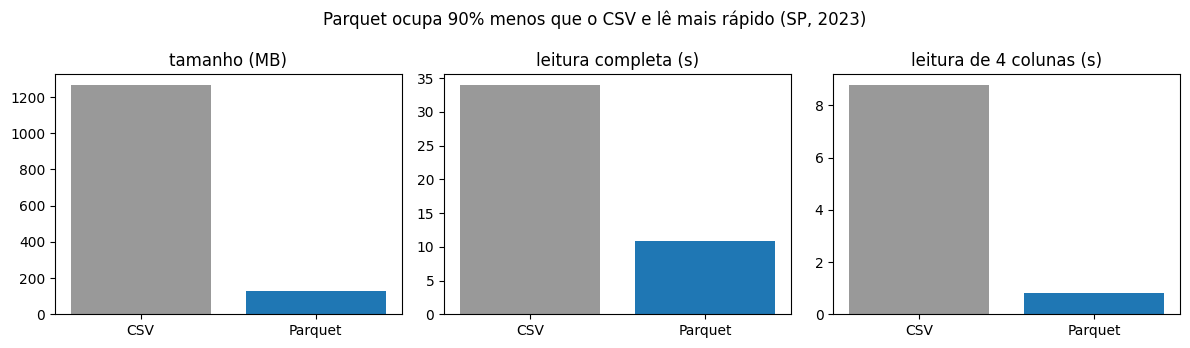

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, res.columns[1:]):
    ax.bar(res.formato, res[col], color=["#999999", "#1f77b4"])
    ax.set_title(col)
reducao = 1 - res.loc[1, "tamanho (MB)"] / res.loc[0, "tamanho (MB)"]
fig.suptitle(f"Parquet ocupa {reducao:.0%} menos que o CSV e lê mais rápido (SP, 2023)")
plt.tight_layout()

### 1.4 Dificuldades da fonte

- **FTP instável:** conexões caem e o servidor recusa conexões paralelas (`425 Cannot open data connection`). Por isso o download é sequencial, com até 5 tentativas e espera exponencial, grava em `.part` e confere o tamanho.
- **Formato DBC:** é um DBF comprimido em formato proprietário e exige o `pyreaddbc`. O `dbfread` converte datas e números por padrão e quebra em data impossível; usamos um parser que devolve texto cru.
- **Documentação espalhada:** o dicionário está num PDF (`IT_SIHSUS_1603.pdf`) e as tabelas de conversão em `.cnv` de largura fixa do TabWin. O `CID10CSV.zip` citado em materiais antigos não existe mais no FTP.
- **População:** o IBGE não publica estimativa municipal para 2023, então esse ano é interpolado (veja o dicionário).
- **Layout entre anos:** resultado na seção 1.2.